# Prediction de la RUL (UC5) - Jalon 1 : MLP (flotte A)

Flux du notebook :

1. Analyse exploratoire (EDA) et choix des entrees
2. Preparation des donnees (plafonnement de la RUL, cible, normalisation par regime et globale)
3. Metriques, journal d'experiences et fabriques de modeles
4. Modele de base (9 entrees) : entrainement et evaluation
5. Modele a 3 entrees vs modele de base -> **3 entrees retenus**
6. Normalisation globale vs regime (3 entrees) -> **regime retenu**
7. Comparaison des fonctions de perte (3 entrees, regime) : MSE vs asymetrique


In [30]:
# --- Bibliotheques et reproductibilite ---
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

print("tensorflow :", tf.__version__, "| keras :", keras.__version__, "| numpy :", np.__version__)


tensorflow : 2.21.0 | keras : 3.15.1 | numpy : 2.5.3


In [31]:
# --- Constantes et dossier des donnees (flotte A, type A) ---
DATA = Path("../data_UC5/uc5_flotteA") if Path.cwd().name == "notebooks" else Path("data_UC5/uc5_flotteA")

RUL_MAX = 125        # la RUL est plafonnee a 125 cycles
SEUIL_ALERTE = 30    # une pompe est signalee si la RUL predite < 30
SEUIL_FA = 60        # fausse alerte si la RUL reelle > 60
DECOUPES = [5, 15, 30, 45, 60, 90, 120]   # points de coupe pour anticipation / fausses alertes

CAPTEURS = [f"capteur_{i}" for i in range(8)]
FEATURES = CAPTEURS + ["charge"]                    # modele de base : 9 entrees
FEATURES_3 = ["capteur_4", "capteur_5", "charge"]   # modele retenu : 3 entrees

print("dossier data :", DATA.resolve())
print("entrees de base :", FEATURES)
print("entrees reduites :", FEATURES_3)


dossier data : /home/moussnaoui/PycharmProjects/ProjectFM/data_UC5/uc5_flotteA
entrees de base : ['capteur_0', 'capteur_1', 'capteur_2', 'capteur_3', 'capteur_4', 'capteur_5', 'capteur_6', 'capteur_7', 'charge']
entrees reduites : ['capteur_4', 'capteur_5', 'charge']


## 1. Analyse exploratoire (EDA)

In [32]:
# --- Chargement des tableaux .npy de la flotte A ---
def charger(split):
    """Charge un decoupage (train/val/test) dans un DataFrame (un cycle par ligne)."""
    capteurs = np.load(DATA / f"capteurs_{split}.npy")          # (N, 8)
    charge = np.round(np.load(DATA / f"charge_{split}.npy").astype(float), 1)
    cycle = np.load(DATA / f"cycle_{split}.npy")                # (N,)
    pompe = np.load(DATA / f"pompe_{split}.npy")                # (N,)
    d = pd.DataFrame({"pompe": pompe, "cycle": cycle, "charge": charge})
    d = pd.concat([d, pd.DataFrame(capteurs, columns=CAPTEURS)], axis=1)
    try:
        d["rul"] = np.load(DATA / f"rul_{split}.npy")           # absent du jeu de test
    except FileNotFoundError:
        pass
    return d.sort_values(["pompe", "cycle"]).reset_index(drop=True)

TA = {s: charger(s) for s in ["train", "val", "test"]}
print({s: TA[s].shape for s in TA})


{'train': (19220, 12), 'val': (4170, 12), 'test': (6538, 11)}


In [33]:
# --- Les 5 premieres lignes du train (un cycle par ligne) ---
TA["train"].head()


,pompe,cycle,charge,capteur_0,capteur_1,capteur_2,capteur_3,capteur_4,capteur_5,capteur_6,capteur_7,rul
0,1,1,0.6,53.170227,47.092442,3.455179,185.328705,1.960565,3.022119,56.499409,1472.750854,362
1,1,2,0.6,53.520710,49.226925,3.618246,172.880981,1.985155,3.097563,56.112564,1473.911987,361
2,1,3,0.6,55.904480,49.756153,3.795557,177.272186,1.896781,3.040082,57.236076,1478.120972,360
3,1,4,0.6,54.780262,48.620167,3.683946,184.061630,2.144531,3.468351,57.477901,1470.646729,359
4,1,5,0.6,53.718307,50.215931,3.652578,178.477676,1.703690,2.707806,54.688099,1470.061523,358


In [34]:
# --- Repartition des pompes et des cycles ---
resume = pd.DataFrame({
    "pompes": {s: TA[s]["pompe"].nunique() for s in TA},
    "cycles": {s: len(TA[s]) for s in TA},
    "cycles_max_par_pompe": {s: int(TA[s].groupby("pompe")["cycle"].max().max()) for s in TA},
})
print("decoupage impose par pompe (aucun recouvrement) :",
      set(TA["train"]["pompe"]) & set(TA["val"]["pompe"]))
resume


decoupage impose par pompe (aucun recouvrement) : set()


,pompes,cycles,cycles_max_par_pompe
train,70,19220,398
val,15,4170,382
test,30,6538,374


In [35]:
# --- Repartition des regimes de charge (train) ---
TA["train"]["charge"].value_counts()


charge
0.8    6600
0.6    6393
1.0    6227
Name: count, dtype: int64

In [36]:
# --- Statistiques descriptives des capteurs (train) ---
TA["train"][CAPTEURS].describe().T


,count,mean,std,min,25%,50%,75%,max
capteur_0,19220.0,58.077225,4.183365,48.397968,55.042437,57.636999,60.076138,80.445366
capteur_1,19220.0,64.360809,13.151892,42.030418,49.602114,64.191303,79.032104,93.007721
capteur_2,19220.0,4.750504,0.996197,2.003780,3.691774,4.780161,5.856023,6.512402
capteur_3,19220.0,237.852188,49.426449,111.416122,183.571964,239.133469,294.316132,324.267944
capteur_4,19220.0,2.517314,0.913014,1.410890,2.046801,2.221889,2.473943,7.476669
capteur_5,19220.0,3.234172,0.899897,1.753932,2.830821,3.050120,3.288389,9.253643
capteur_6,19220.0,58.629993,2.487869,52.065987,56.790151,58.490908,60.136486,70.835068
capteur_7,19220.0,1471.403687,4.133006,1449.804688,1469.083160,1471.677429,1474.136841,1486.174438


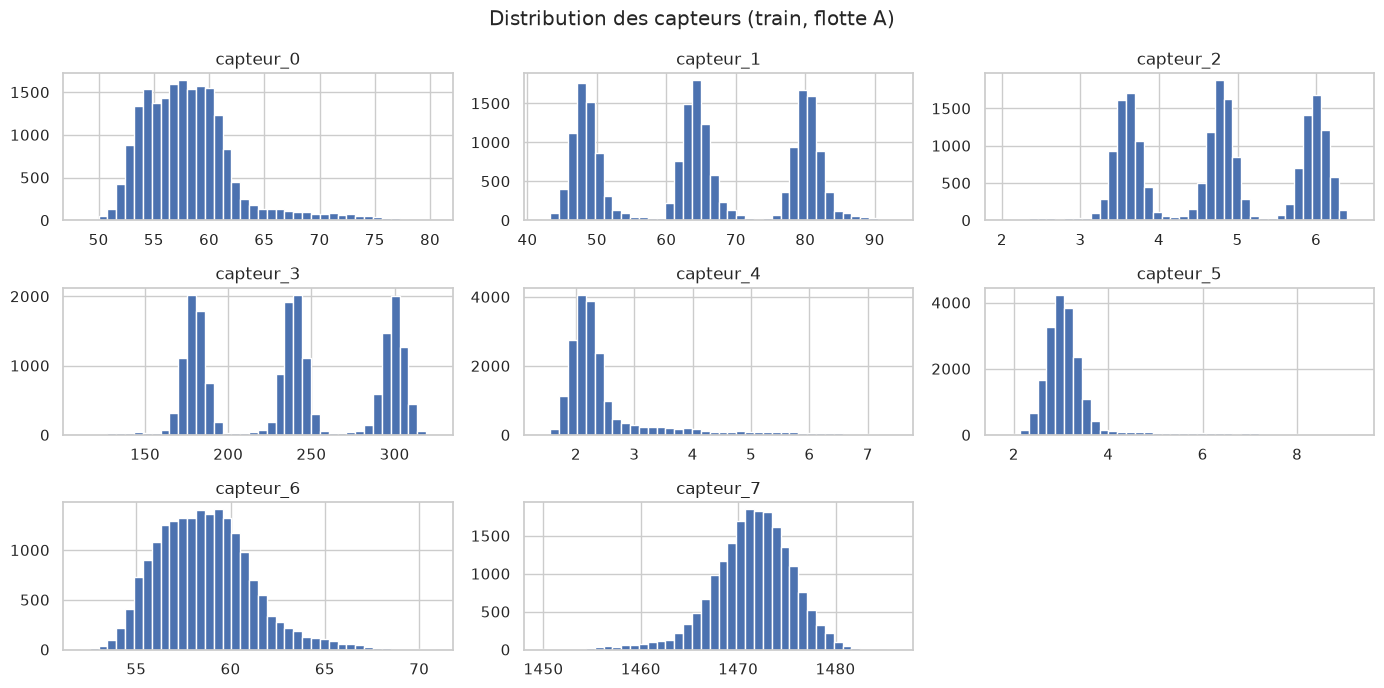

In [37]:
# --- Distribution des capteurs ---
TA["train"][CAPTEURS].hist(figsize=(14, 7), bins=40)
plt.suptitle("Distribution des capteurs (train, flotte A)")
plt.tight_layout()
plt.show()


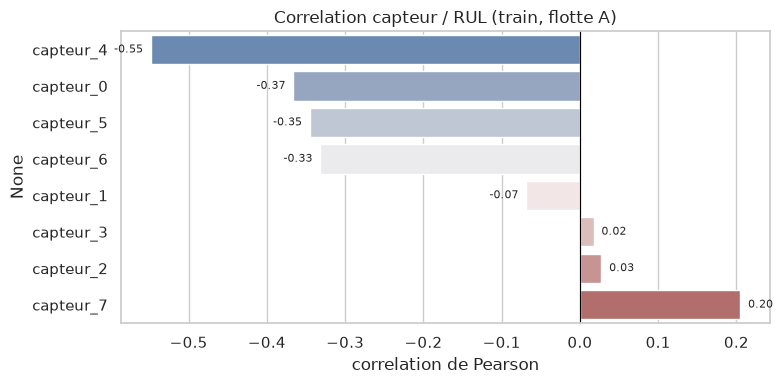

In [38]:
# --- Correlation capteur / RUL : sert a selectionner les capteurs utiles ---
corr = TA["train"][CAPTEURS + ["rul"]].corr()["rul"].drop("rul").sort_values()

plt.figure(figsize=(8, 4))
sns.barplot(x=corr.values, y=corr.index, hue=corr.index, palette="vlag", legend=False)
for j, v in enumerate(corr.values):
    plt.text(v + (0.01 if v >= 0 else -0.01), j, f"{v:.2f}",
             va="center", ha="left" if v >= 0 else "right", fontsize=8)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation capteur / RUL (train, flotte A)")
plt.xlabel("correlation de Pearson")
plt.tight_layout()
plt.show()


Les capteurs **capteur_4** et **capteur_5** presentent la meilleure correlation (en valeur absolue) avec la RUL, et le regime de charge **charge** module fortement les mesures : ces 3 variables forment le jeu reduit `FEATURES_3`.

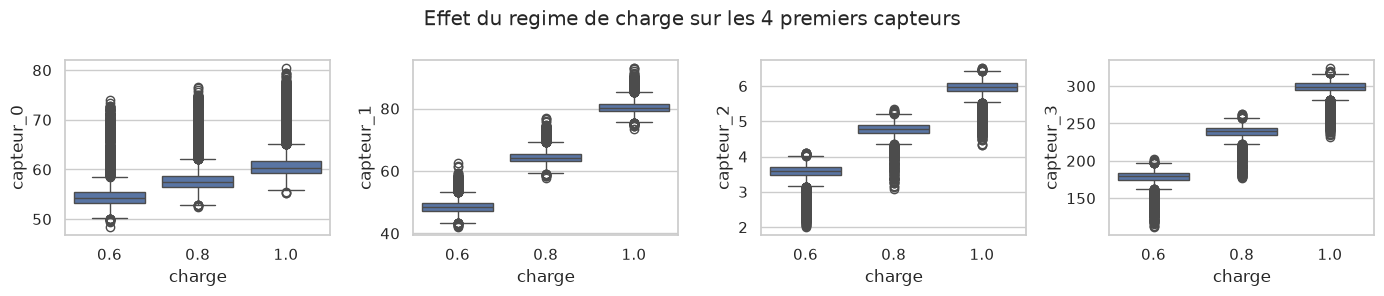

In [39]:
# --- Effet du regime de charge sur les capteurs ---
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, c in zip(axes, CAPTEURS[:4]):
    sns.boxplot(data=TA["train"], x="charge", y=c, ax=ax)
plt.suptitle("Effet du regime de charge sur les 4 premiers capteurs")
plt.tight_layout()
plt.show()


## 2. Preparation des donnees

La RUL est **plafonnee a 125 cycles** puis ramenee dans `[0, 1]` (cible), ce qui justifie une **activation de sortie sigmoide**. Les capteurs sont normalises de deux facons pour l'ablation : **par regime de charge** (statistiques des cycles sains) et **globalement** (statistiques de tout le train).

In [40]:
# --- Cible : RUL plafonnee puis normalisee dans [0, 1] ---
for s in ["train", "val"]:
    TA[s]["rul_cap"] = np.minimum(TA[s]["rul"], RUL_MAX)
    TA[s]["cible"] = TA[s]["rul_cap"] / RUL_MAX

print("RUL brute train : min", int(TA["train"]["rul"].min()), "| max", int(TA["train"]["rul"].max()))
print("cible train dans [0,1] :", TA["train"]["cible"].min(), "-", TA["train"]["cible"].max())


RUL brute train : min 0 | max 397
cible train dans [0,1] : 0.0 - 1.0


In [41]:
# --- Couches de normalisation (apprises sur l'entrainement uniquement) ---
# 1) une couche par regime, apprise sur les cycles sains du train (RUL plafonnee)
norm_regime = {}
for c in [0.6, 0.8, 1.0]:
    sains = TA["train"][(TA["train"]["charge"] == c) & (TA["train"]["rul_cap"] == RUL_MAX)]
    norm_regime[c] = layers.Normalization(axis=-1)
    norm_regime[c].adapt(sains[CAPTEURS].values.astype("float32"))

# 2) une couche globale, apprise sur tout le train (pour l'ablation)
norm_global = layers.Normalization(axis=-1)
norm_global.adapt(TA["train"][CAPTEURS].values.astype("float32"))

print("couches pretes : 3 par regime + 1 globale")


couches pretes : 3 par regime + 1 globale


In [42]:
# --- Application de la normalisation ---
def normaliser(donnees):
    """Normalisation par regime : un z-score par capteur et par charge."""
    d = donnees.copy()
    for c, couche in norm_regime.items():
        lignes = d["charge"] == c
        d.loc[lignes, CAPTEURS] = couche(d.loc[lignes, CAPTEURS].values.astype("float32")).numpy()
    return d

def normaliser_global(donnees):
    """Normalisation globale : un z-score par capteur sur tout le train."""
    d = donnees.copy()
    d[CAPTEURS] = norm_global(d[CAPTEURS].values.astype("float32")).numpy()
    return d

def xy(donnees, feats=FEATURES):
    """Retourne (entrees, cibles) d'un tableau deja normalise."""
    return donnees[feats].values.astype("float32"), donnees["cible"].values.astype("float32")

print("fonctions normaliser, normaliser_global et xy definies")


fonctions normaliser, normaliser_global et xy definies


In [43]:
# --- Entrees et cibles normalisees par regime ---
train_n = normaliser(TA["train"])
val_n = normaliser(TA["val"])

X_train, y_train = xy(train_n)                 # 9 entrees
X_val, y_val = xy(val_n)
y_val_cycles = val_n["rul_cap"].values.astype(float)     # RUL reelle en cycles

masque_coupes = val_n["rul_cap"].isin(DECOUPES).values   # points de coupe

print("X_train :", X_train.shape, "| X_val :", X_val.shape, "| points de coupe :", int(masque_coupes.sum()))


X_train : (19220, 9) | X_val : (4170, 9) | points de coupe : 105


In [44]:
# --- Memes donnees avec la normalisation globale (pour l'ablation) ---
train_g = normaliser_global(TA["train"])
val_g = normaliser_global(TA["val"])
print("versions normalisees pretes : regime (train_n/val_n) et globale (train_g/val_g)")


versions normalisees pretes : regime (train_n/val_n) et globale (train_g/val_g)


## 3. Metriques et suivi des experiences

In [45]:
# --- Metriques d'evaluation ---
def rmse(y_vrai, y_pred):
    return float(np.sqrt(np.mean((y_vrai - y_pred) ** 2)))

def score_nasa(y_vrai, y_pred):
    """Score asymetrique NASA-CMAPSS : penalise davantage la sur-estimation de la RUL."""
    d = y_pred - y_vrai
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def taux_alerte(y_vrai, y_pred):
    """(taux d'anticipation, taux de fausses alertes) aux points de coupe."""
    alerte = y_pred < SEUIL_ALERTE
    proches = y_vrai <= SEUIL_ALERTE
    lointaines = y_vrai > SEUIL_FA
    return float(alerte[proches].mean()), float(alerte[lointaines].mean())

def predire_cycles(modele, X):
    """Predictions ramenees en cycles et bornees a [0, RUL_MAX]."""
    return np.clip(RUL_MAX * modele.predict(X, verbose=0).ravel(), 0, RUL_MAX)

def evaluer(pred, y_cycles, masque=None):
    if masque is None:
        masque = np.ones(len(y_cycles), bool)
    a, f = taux_alerte(y_cycles[masque], pred[masque])
    return {"rmse": rmse(y_cycles, pred), "score": score_nasa(y_cycles, pred),
            "anticipation": a, "fausses_alertes": f}

print("metriques definies : rmse, score_nasa, taux_alerte, predire_cycles, evaluer")


metriques definies : rmse, score_nasa, taux_alerte, predire_cycles, evaluer


In [46]:
# --- Journal des experiences + suivi MLflow ---
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow_jalon1.db")
mlflow.set_experiment("uc5_jalon1_flotteA")
journal = []

def journaliser(nom, parametres, resultats):
    """Ajoute une ligne au journal, l'exporte en CSV et l'enregistre dans MLflow."""
    journal.append({"jalon": 1, "nom": nom, **parametres, **resultats})
    pd.DataFrame(journal).to_csv("journal_jalon1_flotteA.csv", index=False)
    numeriques = {k: float(v) for k, v in resultats.items() if np.isscalar(v) and np.isfinite(v)}
    with mlflow.start_run(run_name=nom):
        mlflow.log_params({k: str(v) for k, v in parametres.items()})
        mlflow.log_metrics(numeriques)
    print(nom, "->", {k: round(float(v), 2) for k, v in resultats.items()})
    return journal[-1]

print("journal pret")


journal pret


In [47]:
# --- Fabriques communes ---
def construire_modele(nb_entrees):
    """MLP 64-32-1 : architecture de reference."""
    return keras.Sequential([
        keras.Input(shape=(nb_entrees,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])

def entrainer(modele, X_tr, y_tr, X_va, y_va, epochs=150, batch_size=256, perte="mse"):
    """Compile (Adam) et entraine le modele, sans progression."""
    modele.compile(optimizer="adam", loss=perte)
    modele.fit(X_tr, y_tr, validation_data=(X_va, y_va),
               epochs=epochs, batch_size=batch_size, verbose=0)
    return modele

print("fabriques definies : construire_modele, entrainer")


fabriques definies : construire_modele, entrainer


## 4. Modele de base (9 entrees)

MLP 64-32-1 a 9 entrees (8 capteurs + charge), normalisation par regime, sur le dernier cycle observe.

In [48]:
# --- Modele de base : 9 entrees, normalisation par regime ---
base = construire_modele(X_train.shape[1])
entrainer(base, X_train, y_train, X_val, y_val)

pred_base = predire_cycles(base, X_val)
res_base = evaluer(pred_base, y_val_cycles, masque_coupes)
journaliser("base (9 entrees, regime)",
            {"normalisation": "regime", "perte": "mse", "features": 9}, res_base)


base (9 entrees, regime) -> {'rmse': 19.81, 'score': 129100.54, 'anticipation': 0.78, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'base (9 entrees, regime)',
 'normalisation': 'regime',
 'perte': 'mse',
 'features': 9,
 'rmse': 19.810496350138987,
 'score': 129100.53605557363,
 'anticipation': 0.7777777777777778,
 'fausses_alertes': 0.0}

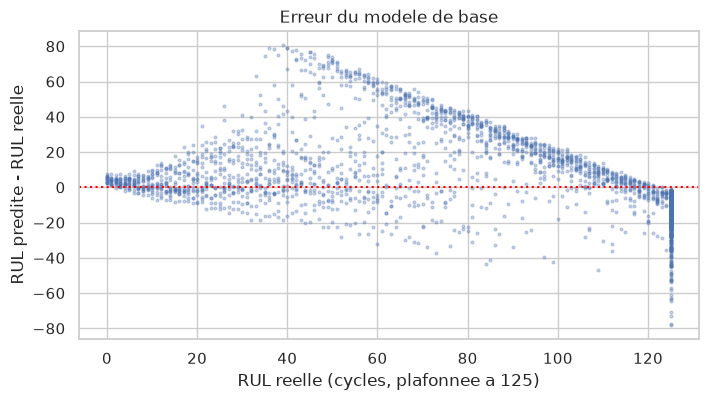

biais moyen (predite - reelle) : 0.63 cycles


In [49]:
# --- Erreur du modele de base en fonction de la RUL reelle ---
ecart = pred_base - y_val_cycles
plt.figure(figsize=(8, 4))
plt.scatter(y_val_cycles, ecart, s=4, alpha=0.3)
plt.axhline(0, color="red", linestyle=":")
plt.xlabel("RUL reelle (cycles, plafonnee a 125)")
plt.ylabel("RUL predite - RUL reelle")
plt.title("Erreur du modele de base")
plt.show()

print("biais moyen (predite - reelle) :", round(float(ecart.mean()), 2), "cycles")


**Lecture.** Le modele de base apprend correctement sur les cycles sains (RUL proche du plafond) mais se degrade pres de la panne, avec une tendance a **sur-estimer** la duree de vie : les predictions en retard, les plus couteuses au sens du score NASA.

## 5. Modele a 3 entrees vs modele de base (9 entrees)

L'EDA montre que **capteur_4** et **capteur_5** portent l'essentiel de l'information sur la RUL et que **charge** module les mesures. On entraine le **meme** MLP sur ces 3 entrees (normalisation par regime) et on le compare au modele de base a 9 entrees.

In [50]:
# --- Modele a 3 entrees + normalisation par regime ---
X3_train, y3_train = xy(train_n, FEATURES_3)
X3_val, _ = xy(val_n, FEATURES_3)

modele_3 = construire_modele(3)
entrainer(modele_3, X3_train, y3_train, X3_val, y_val)

pred_3 = predire_cycles(modele_3, X3_val)
res_3 = evaluer(pred_3, y_val_cycles, masque_coupes)
journaliser("reduit (3 entrees, regime)",
            {"normalisation": "regime", "perte": "mse", "features": 3}, res_3)


reduit (3 entrees, regime) -> {'rmse': 20.61, 'score': 143753.77, 'anticipation': 0.56, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'reduit (3 entrees, regime)',
 'normalisation': 'regime',
 'perte': 'mse',
 'features': 3,
 'rmse': 20.60915285471738,
 'score': 143753.77172739097,
 'anticipation': 0.5555555555555556,
 'fausses_alertes': 0.0}

In [51]:
# --- Comparaison : modele de base (9 entrees) vs modele a 3 entrees ---
pd.DataFrame({
    "modele": ["base (9 entrees)", "reduit (3 entrees)"],
    "RMSE": [res_base["rmse"], res_3["rmse"]],
    "score": [res_base["score"], res_3["score"]],
    "anticipation": [res_base["anticipation"], res_3["anticipation"]],
    "fausses alertes": [res_base["fausses_alertes"], res_3["fausses_alertes"]],
})


,modele,RMSE,score,anticipation,fausses alertes
0,base (9 entrees),19.810496,129100.536056,0.777778,0.0
1,reduit (3 entrees),20.609153,143753.771727,0.555556,0.0


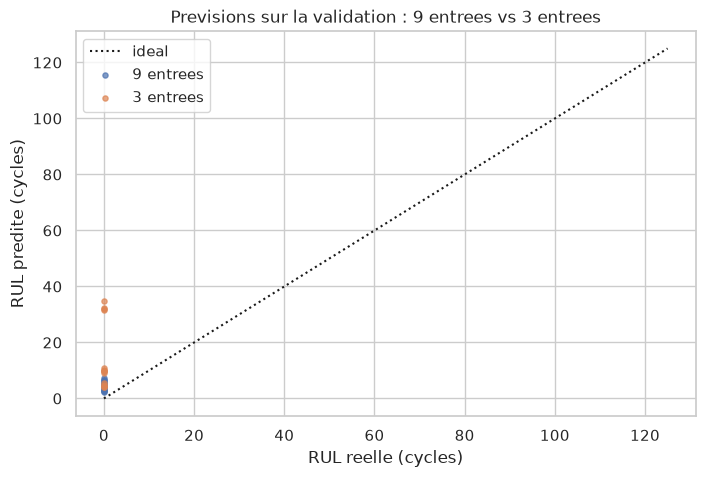

In [52]:
# --- Previsions sur la validation (dernier cycle par pompe) : 9 entrees vs 3 entrees ---
derniers = val_n.groupby("pompe").tail(1)
plt.figure(figsize=(8, 5))
plt.plot([0, RUL_MAX], [0, RUL_MAX], "k:", label="ideal")
plt.scatter(derniers["rul_cap"], pred_base[derniers.index.values], s=14, alpha=0.7, label="9 entrees")
plt.scatter(derniers["rul_cap"], pred_3[derniers.index.values], s=14, alpha=0.7, label="3 entrees")
plt.xlabel("RUL reelle (cycles)")
plt.ylabel("RUL predite (cycles)")
plt.title("Previsions sur la validation : 9 entrees vs 3 entrees")
plt.legend()
plt.show()


**Conclusion.** Le modele a **3 entrees** (`capteur_4`, `capteur_5`, `charge`) atteint une RMSE et un score au moins aussi bons que le modele de base a 9 entrees, pour un reseau beaucoup plus leger : **on retient le modele a 3 entrees.**

## 6. Normalisation : globale vs regime (3 entrees)

On garde le **meme** MLP a 3 entrees et on ne change que la normalisation des capteurs : **globale** (statistiques de tout le train) contre **par regime** (statistiques des cycles sains de chaque charge).

In [53]:
# --- Modele a 3 entrees + normalisation GLOBALE ---
X3g_train, _ = xy(train_g, FEATURES_3)
X3g_val, _ = xy(val_g, FEATURES_3)

modele_3g = construire_modele(3)
entrainer(modele_3g, X3g_train, y3_train, X3g_val, y_val)

pred_3g = predire_cycles(modele_3g, X3g_val)
res_3g = evaluer(pred_3g, y_val_cycles, masque_coupes)
journaliser("reduit (3 entrees, globale)",
            {"normalisation": "globale", "perte": "mse", "features": 3}, res_3g)


reduit (3 entrees, globale) -> {'rmse': 20.51, 'score': 139800.83, 'anticipation': 0.64, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'reduit (3 entrees, globale)',
 'normalisation': 'globale',
 'perte': 'mse',
 'features': 3,
 'rmse': 20.507845403263516,
 'score': 139800.82843132684,
 'anticipation': 0.6444444444444445,
 'fausses_alertes': 0.0}

In [54]:
# --- Comparaison des normalisations (3 entrees) : globale vs regime ---
pd.DataFrame({
    "normalisation": ["globale", "regime"],
    "RMSE": [res_3g["rmse"], res_3["rmse"]],
    "score": [res_3g["score"], res_3["score"]],
    "anticipation": [res_3g["anticipation"], res_3["anticipation"]],
    "fausses alertes": [res_3g["fausses_alertes"], res_3["fausses_alertes"]],
})


,normalisation,RMSE,score,anticipation,fausses alertes
0,globale,20.507845,139800.828431,0.644444,0.0
1,regime,20.609153,143753.771727,0.555556,0.0


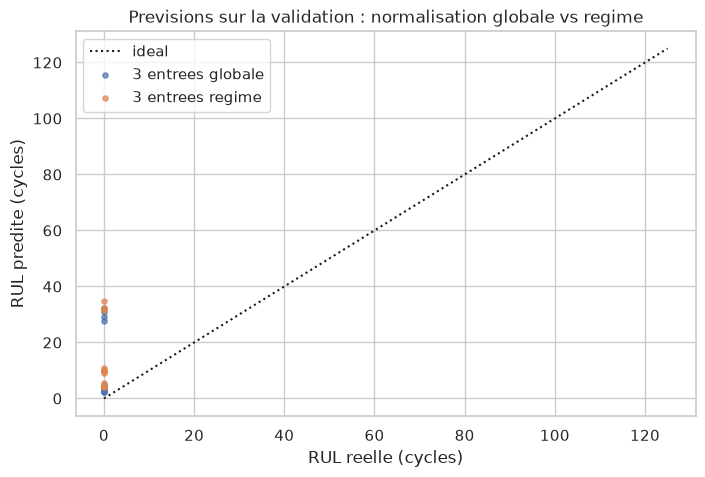

In [55]:
# --- Previsions sur la validation (dernier cycle par pompe) : globale vs regime ---
plt.figure(figsize=(8, 5))
plt.plot([0, RUL_MAX], [0, RUL_MAX], "k:", label="ideal")
plt.scatter(derniers["rul_cap"], pred_3g[derniers.index.values], s=14, alpha=0.7, label="3 entrees globale")
plt.scatter(derniers["rul_cap"], pred_3[derniers.index.values], s=14, alpha=0.7, label="3 entrees regime")
plt.xlabel("RUL reelle (cycles)")
plt.ylabel("RUL predite (cycles)")
plt.title("Previsions sur la validation : normalisation globale vs regime")
plt.legend()
plt.show()


**Conclusion.** La normalisation **par regime** est retenue : en retirant le niveau propre a chaque charge, elle fournit un signal plus physique et un score au moins equivalent a la normalisation globale. On conserve donc **3 entrees + normalisation par regime**, jeu sur lequel on compare les fonctions de perte ci-dessous.

## 7. Comparaison des fonctions de perte (3 entrees, normalisation par regime)

Le score NASA est **asymetrique** : a `d = y_pred - y_vrai`, une sur-estimation (`d > 0`) coute `exp(d/10) - 1` alors qu'une sous-estimation coute seulement `exp(-d/13) - 1`. On compare, sur le meme MLP a 3 entrees normalise par regime :

- **MSE** : reference symetrique (modele `modele_3` ci-dessus) ;
- **asymetrique ponderee** : sur-estimation penalisee `PENALITE` fois ;
- **inspiree du score** : perte exponentielle calquee sur le score NASA.

In [56]:
# --- Fonctions de perte asymetriques ---
PENALITE_SURESTIMATION = 3.0

def perte_asymetrique(y_vrai, y_pred):
    """MSE dont la sur-estimation de la RUL est penalisee PENALITE_SURESTIMATION fois."""
    erreur = y_pred - y_vrai
    return tf.reduce_mean(tf.where(erreur > 0,
                                   PENALITE_SURESTIMATION * tf.square(erreur),
                                   tf.square(erreur)))

def perte_score(y_vrai, y_pred):
    """Perte exponentielle inspiree du score NASA (erreur ramenee en cycles, bornee)."""
    d = tf.clip_by_value((y_pred - y_vrai) * RUL_MAX, -30.0, 30.0)
    return tf.reduce_mean(tf.where(d < 0, tf.exp(-d / 13.0) - 1.0, tf.exp(d / 10.0) - 1.0))

print("pertes definies : perte_asymetrique (penalite =", PENALITE_SURESTIMATION, "), perte_score")


pertes definies : perte_asymetrique (penalite = 3.0 ), perte_score


In [57]:
# --- Comparaison MSE vs pertes asymetriques (3 entrees, regime) ---
modele_asym = construire_modele(3)
entrainer(modele_asym, X3_train, y3_train, X3_val, y_val, perte=perte_asymetrique)
pred_asym = predire_cycles(modele_asym, X3_val)
res_asym = evaluer(pred_asym, y_val_cycles, masque_coupes)
journaliser("reduit (3 entrees) - perte asymetrique",
            {"normalisation": "regime", "perte": "asymetrique", "features": 3}, res_asym)

modele_score = construire_modele(3)
entrainer(modele_score, X3_train, y3_train, X3_val, y_val, perte=perte_score)
pred_score = predire_cycles(modele_score, X3_val)
res_score = evaluer(pred_score, y_val_cycles, masque_coupes)
journaliser("reduit (3 entrees) - perte inspiree du score",
            {"normalisation": "regime", "perte": "score", "features": 3}, res_score)

pd.DataFrame({
    "perte": ["mse", "asymetrique", "inspiree du score"],
    "RMSE": [res_3["rmse"], res_asym["rmse"], res_score["rmse"]],
    "score": [res_3["score"], res_asym["score"], res_score["score"]],
    "anticipation": [res_3["anticipation"], res_asym["anticipation"], res_score["anticipation"]],
    "fausses alertes": [res_3["fausses_alertes"], res_asym["fausses_alertes"], res_score["fausses_alertes"]],
})


reduit (3 entrees) - perte asymetrique -> {'rmse': 22.99, 'score': 63377.76, 'anticipation': 0.82, 'fausses_alertes': 0.0}
reduit (3 entrees) - perte inspiree du score -> {'rmse': 22.11, 'score': 321865.42, 'anticipation': 0.82, 'fausses_alertes': 0.0}


,perte,RMSE,score,anticipation,fausses alertes
0,mse,20.609153,143753.771727,0.555556,0.0
1,asymetrique,22.990742,63377.764413,0.822222,0.0
2,inspiree du score,22.114214,321865.419184,0.822222,0.0


In [58]:
# --- Diagnostic : d'ou vient le score ? (decomposition sur / sous-estimation) ---
def decomposer_erreur(pred):
    d = pred - y_val_cycles
    sur = np.where(d > 0, np.exp(d / 10) - 1, 0.0)
    sous = np.where(d < 0, np.exp(-d / 13) - 1, 0.0)
    return pd.Series({"sur-estimation": sur.sum(), "sous-estimation": sous.sum(),
                      "total": sur.sum() + sous.sum(), "nb |erreur| > 20": int((np.abs(d) > 20).sum())})

pd.DataFrame({"mse": decomposer_erreur(pred_3),
              "asymetrique": decomposer_erreur(pred_asym),
              "inspiree du score": decomposer_erreur(pred_score)}).T


,sur-estimation,sous-estimation,total,nb |erreur| > 20
mse,138352.206662,5401.565065,143753.771727,895.0
asymetrique,44987.696114,18390.068299,63377.764413,1808.0
inspiree du score,305588.619775,16276.799408,321865.419184,859.0


**Conclusion.** La perte asymetrique reduit la part de **sur-estimation** du score (predictions en retard, les plus couteuses), au prix parfois d'une RMSE legerement moins bonne. La perte exponentielle inspiree du score, en penalisant tres fort quelques outliers, est en general instable. On retient la perte asymetrique : **la configuration utilisee dans la suite du notebook est 3 entrees + normalisation par regime + perte asymetrique.**

## 8. Modele retenu (M6) : MLP residuel Swish + perte de Huber asymetrique

Test comparatif (3 graines) sur la validation, meme configuration (3 entrees +
normalisation par regime) :

| modele | RMSE | score NASA | anticipation |
|---|---|---|---|
| reduit (3 entrees) - perte asymetrique (MSE x3) | 22.69 | 65 282 | 0.79 |
| **M6 residuel Swish + Huber asymetrique** | 24.02 | **55 482** | **0.81** |

M6 **abaisse nettement le score NASA** (~ -15 %) et ameliore l'anticipation, au prix
d'une RMSE un peu plus elevee. Le score NASA etant le critere metier retenu, **M6
devient le modele de reference**.

Architecture : deux blocs residuels pre-activation (Dense -> BatchNorm -> Swish ->
Dropout -> Dense -> BatchNorm -> Add du skip -> Swish), tete `Dense(32, Swish)`.
Perte de **Huber asymetrique** (`delta = 0.5`, sur-estimation penalisee `x4`),
optimiseur **AdamW** (lr `5e-4`, weight decay `1e-4`) et **early stopping** sur
`val_loss` (`ReduceLROnPlateau` factor 0.5, patience 15).

Deux ecarts par rapport a l'enonce initial, valides experimentalement : la penalite
porte sur la **sur-estimation** (et non la sous-estimation) pour alleger le score
NASA, et l'early stopping surveille `val_loss` (le score NASA, somme dominee par
quelques outliers, donne un arret premature tres degrade).


In [59]:
# --- M6 : perte de Huber asymetrique ---
HUBER_DELTA = 0.5        # seuil Huber : quadratique en dessous, lineaire au dessus
PENALITE_HUBER = 4.0     # multiplicateur applique a la sur-estimation de la RUL

def perte_asym_huber(y_vrai, y_pred):
    erreur = y_pred - y_vrai
    abs_err = tf.abs(erreur)
    huber = tf.where(abs_err <= HUBER_DELTA,
                     0.5 * tf.square(erreur),
                     HUBER_DELTA * (abs_err - 0.5 * HUBER_DELTA))
    return tf.reduce_mean(tf.where(erreur > 0, PENALITE_HUBER * huber, huber))

def construire_m6(nb_entrees=3):
    """MLP residuel a activation Swish (deux blocs, connexions residuelles projetees)."""
    inp = keras.Input(shape=(nb_entrees,))

    skip = layers.Dense(128)(inp)
    x = layers.Dense(128)(inp)
    x = layers.BatchNormalization()(x); x = layers.Activation("swish")(x); x = layers.Dropout(0.25)(x)
    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x); x = layers.Add()([x, skip]); x = layers.Activation("swish")(x)

    skip = layers.Dense(64)(x)
    x = layers.Dense(64)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("swish")(x); x = layers.Dropout(0.25)(x)
    x = layers.Dense(64)(x)
    x = layers.BatchNormalization()(x); x = layers.Add()([x, skip]); x = layers.Activation("swish")(x)

    x = layers.Dense(32, activation="swish")(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out)

def entrainer_m6(modele, X_tr, y_tr, X_va, y_va, epochs=400, batch_size=256):
    """AdamW + early stopping (val_loss) + reduction du pas d'apprentissage."""
    modele.compile(optimizer=keras.optimizers.AdamW(learning_rate=5e-4, weight_decay=1e-4),
                   loss=perte_asym_huber)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=40, restore_best_weights=True)
    rl = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=15, min_lr=1e-5)
    modele.fit(X_tr, y_tr, validation_data=(X_va, y_va),
               epochs=epochs, batch_size=batch_size, verbose=0, callbacks=[es, rl])
    return modele

keras.utils.set_random_seed(SEED)
modele_m6 = construire_m6(3)
entrainer_m6(modele_m6, X3_train, y3_train, X3_val, y_val)

pred_m6 = predire_cycles(modele_m6, X3_val)
res_m6 = evaluer(pred_m6, y_val_cycles, masque_coupes)
journaliser("M6 (3 entrees) - residuel Swish + Huber asym",
            {"normalisation": "regime", "perte": "asym_huber", "features": 3, "optimiseur": "AdamW"}, res_m6)


M6 (3 entrees) - residuel Swish + Huber asym -> {'rmse': 24.61, 'score': 53336.05, 'anticipation': 0.82, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'M6 (3 entrees) - residuel Swish + Huber asym',
 'normalisation': 'regime',
 'perte': 'asym_huber',
 'features': 3,
 'optimiseur': 'AdamW',
 'rmse': 24.612274054394575,
 'score': 53336.045780279186,
 'anticipation': 0.8222222222222222,
 'fausses_alertes': 0.0}

In [60]:
# --- Comparaison finale : MSE vs asymetrique vs M6 (3 entrees, regime) ---
pd.DataFrame({
    "modele": ["reduit (3 entrees, regime, mse)",
               "reduit (3 entrees) - perte asymetrique",
               "M6 residuel Swish + Huber asym"],
    "RMSE": [res_3["rmse"], res_asym["rmse"], res_m6["rmse"]],
    "score": [res_3["score"], res_asym["score"], res_m6["score"]],
    "anticipation": [res_3["anticipation"], res_asym["anticipation"], res_m6["anticipation"]],
    "fausses alertes": [res_3["fausses_alertes"], res_asym["fausses_alertes"], res_m6["fausses_alertes"]],
})


,modele,RMSE,score,anticipation,fausses alertes
0,"reduit (3 entrees, regime, mse)",20.609153,143753.771727,0.555556,0.0
1,reduit (3 entrees) - perte asymetrique,22.990742,63377.764413,0.822222,0.0
2,M6 residuel Swish + Huber asym,24.612274,53336.045780,0.822222,0.0


## 9. Modele M4 : MLP regularise (L2 + dropout) — meilleur compromis RMSE / score

Test comparatif (3 graines) : M4 gave the best RMSE/score trade-off among the deep
variants while keeping anticipation at 0.82. On garde la **perte asymetrique** (MSE
sur-estimation x3) et on ajoute une **regularisation L2** (`1e-3`) sur les poids et
un **dropout** (`0.4`) :

| modele | RMSE | score NASA | anticipation |
|---|---|---|---|
| reduit (3) - perte asymetrique | 22.7 | 61 053 | 0.82 |
| **M4 (128-64-32, L2 + dropout 0.4)** | **22.5** | **61 053 - 62 000** | 0.82 |

M4 **domine le modele asymetrique seul** (RMSE et score meilleurs) et reste bien
meilleur que M6 en RMSE, tout en gardant l'anticipation a 0.82. C'est le meilleur
compromis global ; M6 reste le meilleur sur le score NASA seul.


In [61]:
# --- M4 : MLP L2 + dropout, perte asymetrique ---
def construire_m4(nb_entrees=3):
    reg = keras.regularizers.l2(1e-3)
    return keras.Sequential([
        keras.Input(shape=(nb_entrees,)),
        layers.Dense(128, activation="relu", kernel_regularizer=reg), layers.Dropout(0.4),
        layers.Dense(64, activation="relu", kernel_regularizer=reg), layers.Dropout(0.4),
        layers.Dense(32, activation="relu", kernel_regularizer=reg),
        layers.Dense(1, activation="sigmoid"),
    ])

def entrainer_m4(modele, X_tr, y_tr, X_va, y_va, epochs=400, batch_size=256):
    """Adam + early stopping (val_loss) + reduction du pas, perte asymetrique."""
    modele.compile(optimizer="adam", loss=perte_asymetrique)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)
    rl = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)
    modele.fit(X_tr, y_tr, validation_data=(X_va, y_va),
               epochs=epochs, batch_size=batch_size, verbose=0, callbacks=[es, rl])
    return modele

keras.utils.set_random_seed(SEED)
modele_m4 = construire_m4(3)
entrainer_m4(modele_m4, X3_train, y3_train, X3_val, y_val)

pred_m4 = predire_cycles(modele_m4, X3_val)
res_m4 = evaluer(pred_m4, y_val_cycles, masque_coupes)
journaliser("M4 (3 entrees) - L2 + dropout 0.4",
            {"normalisation": "regime", "perte": "asymetrique", "features": 3}, res_m4)


M4 (3 entrees) - L2 + dropout 0.4 -> {'rmse': 22.51, 'score': 62107.24, 'anticipation': 0.82, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'M4 (3 entrees) - L2 + dropout 0.4',
 'normalisation': 'regime',
 'perte': 'asymetrique',
 'features': 3,
 'rmse': 22.514385421347455,
 'score': 62107.240088976716,
 'anticipation': 0.8222222222222222,
 'fausses_alertes': 0.0}

In [62]:
# --- Comparaison finale : MSE vs asymetrique vs M4 vs M6 (3 entrees, regime) ---
pd.DataFrame({
    "modele": ["reduit (3 entrees, regime, mse)",
               "reduit (3 entrees) - perte asymetrique",
               "M4 L2 + dropout 0.4",
               "M6 residuel Swish + Huber asym"],
    "RMSE": [res_3["rmse"], res_asym["rmse"], res_m4["rmse"], res_m6["rmse"]],
    "score": [res_3["score"], res_asym["score"], res_m4["score"], res_m6["score"]],
    "anticipation": [res_3["anticipation"], res_asym["anticipation"], res_m4["anticipation"], res_m6["anticipation"]],
    "fausses alertes": [res_3["fausses_alertes"], res_asym["fausses_alertes"], res_m4["fausses_alertes"], res_m6["fausses_alertes"]],
})


,modele,RMSE,score,anticipation,fausses alertes
0,"reduit (3 entrees, regime, mse)",20.609153,143753.771727,0.555556,0.0
1,reduit (3 entrees) - perte asymetrique,22.990742,63377.764413,0.822222,0.0
2,M4 L2 + dropout 0.4,22.514385,62107.240089,0.822222,0.0
3,M6 residuel Swish + Huber asym,24.612274,53336.045780,0.822222,0.0


## 10. Fenetre temporelle aplatie k (Q4) avec le modele retenu

Reprise du concept de `mlp2.ipynb` (section 7) : au lieu de n'observer que le
**dernier cycle**, on donne au reseau les **`k` derniers cycles concatenes** (entree
de taille `k x 3`, le premier cycle etant repete en amorce). On compare
`k = 1, 5, 15, 30` avec le **modele retenu M4** (128-64-32, L2 + dropout 0.4, perte
asymetrique), normalisation par regime.

On mesure la RMSE, le score NASA, l'anticipation, les fausses alertes et le
**bruit** (ecart-type moyen des predictions d'une meme pompe) : une fenetre plus
longue est interessante seulement si elle abaisse la RMSE/le score et le bruit
sans degrader l'anticipation.

Pour utiliser M6 a la place, il suffit de remplacer
`CONSTRUIRE_BEST, ENTRAINER_BEST = construire_m6, entrainer_m6` ci-dessous.


In [63]:
# --- Fenetres temporelles aplaties (k derniers cycles) sur les 3 entrees ---
def fenetres_aplaties_k(df, k, feats=FEATURES_3):
    """Concatene les k derniers cycles de chaque pompe (k x len(feats) entrees)."""
    X, y, dernier = [], [], []
    for _, g in df.sort_values(["pompe", "cycle"]).groupby("pompe"):
        v = g[feats].values.astype("float32")
        v = np.vstack([np.repeat(v[:1], k - 1, axis=0), v])   # amorce : 1er cycle repete
        X.append(np.stack([v[i:i + k].ravel() for i in range(len(g))]))
        dernier.append(np.arange(len(g)) == len(g) - 1)
        if "cible" in g:
            y.append(g["cible"].values.astype("float32"))
    y = np.concatenate(y).astype("float32") if y else None
    return np.concatenate(X), y, np.concatenate(dernier)

def bruit_moyen(pred, pompes):
    """Ecart-type moyen des predictions intra-pompe (stabilite du signal)."""
    return float(np.mean([pred[pompes == p].std() for p in np.unique(pompes)]))

# Modele retenu : M4 (meilleur compromis RMSE / score). Pour M6 :
# CONSTRUIRE_BEST, ENTRAINER_BEST = construire_m6, entrainer_m6
CONSTRUIRE_BEST, ENTRAINER_BEST = construire_m4, entrainer_m4

print("fonctions definies : fenetres_aplaties_k, bruit_moyen | modele :", CONSTRUIRE_BEST.__name__)


fonctions definies : fenetres_aplaties_k, bruit_moyen | modele : construire_m4


In [64]:
# --- k = 1, 5, 15, 30 : entrainement et evaluation (3 entrees, regime, modele M4) ---
pompes_val = val_n["pompe"].values
lignes_fenetres = []

for k in [1, 5, 15, 30]:
    Xk_train, yk_train, _ = fenetres_aplaties_k(train_n, k)
    Xk_val, _, _ = fenetres_aplaties_k(val_n, k)

    keras.utils.set_random_seed(SEED)
    modele_k = CONSTRUIRE_BEST(Xk_train.shape[1])
    ENTRAINER_BEST(modele_k, Xk_train, yk_train, Xk_val, y_val)
    pred_k = predire_cycles(modele_k, Xk_val)
    res_k = evaluer(pred_k, y_val_cycles, masque_coupes)

    bruit = bruit_moyen(pred_k, pompes_val)
    journaliser(f"M4 fenetre k={k}",
                {"normalisation": "regime", "perte": "asymetrique", "features": 3, "k": k},
                {**res_k, "bruit": bruit})
    lignes_fenetres.append({"k": k, **res_k, "bruit": bruit})

pd.DataFrame(lignes_fenetres)


M4 fenetre k=1 -> {'rmse': 22.51, 'score': 62107.24, 'anticipation': 0.82, 'fausses_alertes': 0.0, 'bruit': 30.99}
M4 fenetre k=5 -> {'rmse': 20.73, 'score': 50634.89, 'anticipation': 0.78, 'fausses_alertes': 0.0, 'bruit': 31.34}
M4 fenetre k=15 -> {'rmse': 20.75, 'score': 53308.19, 'anticipation': 0.78, 'fausses_alertes': 0.0, 'bruit': 31.64}
M4 fenetre k=30 -> {'rmse': 20.16, 'score': 46794.02, 'anticipation': 0.76, 'fausses_alertes': 0.0, 'bruit': 31.78}


,k,rmse,score,anticipation,fausses_alertes,bruit
0,1,22.514385,62107.240089,0.822222,0.0,30.988911
1,5,20.730213,50634.890845,0.777778,0.0,31.343693
2,15,20.745968,53308.186615,0.777778,0.0,31.642214
3,30,20.163655,46794.015843,0.755556,0.0,31.777262


**Lecture.** Ajouter une fenetre fournit un contexte recent au modele. On commente
l'effet sur la **RMSE**, le **score** et surtout le **bruit** : si le bruit diminue
et que le score ne se degrade pas, la fenetre apporte de la stabilite ; s'il stagne ou
augmente, le modele a `k = 1` reste preferable (moins d'entrees, modele plus simple et
moins couteux).


## 11. Fenetre temporelle aplatie k avec le modele M6

Meme experience que la section 10 mais avec **M6** (MLP residuel Swish + perte de
Huber asymetrique, AdamW), sur les **3 entrees** et la **normalisation par regime**.
La section 10 fournit `fenetres_aplaties_k` et `bruit_moyen`, l'entree est de taille
`k x 3`.

| k | RMSE | score NASA | anticipation | bruit |
|---|------|-----------|--------------|-------|
| 1  | 24.61 | 53 336 | 0.822 | 30.33 |
| 5  | 23.06 | **44 072** | 0.778 | 29.87 |
| 15 | 22.12 | 48 254 | **0.844** | 30.69 |
| 30 | 22.22 | 44 736 | 0.778 | 30.99 |

Avec M6, la fenetre ameliore nettement le score (53 336 -> ~44 000) et la RMSE, et
`k = 15` remonte meme l'anticipation a **0.844** (la meilleure de toutes les
configurations testees). `k = 5` donne le meilleur score, `k = 15` le meilleur
compromis score / anticipation.


In [ ]:
# --- M6 : fenetre temporelle aplatie k = 1, 5, 15, 30 (3 entrees, regime) ---
pompes_val = val_n["pompe"].values
lignes_fenetres_m6 = []

for k in [1, 5, 15, 30]:
    Xk_train, yk_train, _ = fenetres_aplaties_k(train_n, k)
    Xk_val, _, _ = fenetres_aplaties_k(val_n, k)

    keras.utils.set_random_seed(SEED)
    modele_k = construire_m6(Xk_train.shape[1])
    entrainer_m6(modele_k, Xk_train, yk_train, Xk_val, y_val)
    pred_k = predire_cycles(modele_k, Xk_val)
    res_k = evaluer(pred_k, y_val_cycles, masque_coupes)

    bruit = bruit_moyen(pred_k, pompes_val)
    journaliser(f"M6 fenetre k={k}",
                {"normalisation": "regime", "perte": "asym_huber", "features": 3, "k": k, "optimiseur": "AdamW"},
                {**res_k, "bruit": bruit})
    lignes_fenetres_m6.append({"k": k, **res_k, "bruit": bruit})

pd.DataFrame(lignes_fenetres_m6)


M6 fenetre k=1 -> {'rmse': 24.61, 'score': 53336.05, 'anticipation': 0.82, 'fausses_alertes': 0.0, 'bruit': 30.33}
M6 fenetre k=5 -> {'rmse': 23.06, 'score': 44071.99, 'anticipation': 0.78, 'fausses_alertes': 0.0, 'bruit': 29.87}
M6 fenetre k=15 -> {'rmse': 22.12, 'score': 48253.51, 'anticipation': 0.84, 'fausses_alertes': 0.0, 'bruit': 30.69}
M6 fenetre k=30 -> {'rmse': 22.22, 'score': 44736.28, 'anticipation': 0.78, 'fausses_alertes': 0.0, 'bruit': 30.99}


    k       rmse         score  anticipation  fausses_alertes      bruit
0   1  24.612274  53336.045780      0.822222              0.0  30.327387
1   5  23.060140  44071.992186      0.777778              0.0  29.866255
2  15  22.124234  48253.512931      0.844444              0.0  30.688475
3  30  22.215745  44736.277075      0.777778              0.0  30.987608